# RF-DETR Inference + Kalman Filter + Fish Hunger Assessment

This notebook demonstrates:
1. **RF-DETR Model Loading & Inference**: Load RF-DETR and run per-frame detection
2. **Kalman Filtering**: Apply LogNormalKalmanFilter to smooth feed area measurements
3. **Feed Consumption Analysis**: Calculate consumption rate and trajectory
4. **Hunger Level Assessment**: Evaluate fish hunger level based on consumption patterns
5. **2D Visualization**: Plot raw vs filtered feed area with hunger indicators

## 1. Setup and Configuration

In [142]:
import warnings
import os

# Suppress transformers deprecation warnings
warnings.filterwarnings('ignore', message='.*use_return_dict.*')
warnings.filterwarnings('ignore', category=DeprecationWarning)

# Suppress transformers logging
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import logging
logging.getLogger('transformers').setLevel(logging.ERROR)
logging.getLogger('transformers.modeling_utils').setLevel(logging.ERROR)

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from datetime import datetime, timezone
import sys

# Set matplotlib defaults
plt.rcParams['font.sans-serif'] = ['DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.figsize'] = (16, 6)

# Project imports
import sys
sys.path.insert(0, str(Path.cwd().parent))

from core.infer.rfdetr_detector import RFDETRDetector
from core.infer.kalman_filter import create_kalman_filter, KalmanFilterConfig
from core.types import Detection, DetectionResult, CLASS_NAMES

print('✓ All imports successful')

✓ All imports successful


In [143]:
# Configuration Parameters
CONFIG = {
    'video_path': '../data/toilet1.mp4',
    'model_path': '../models/rf-detr-fish-regular.pth',
    'confidence_threshold': 0.3,
    'device': 'cuda',
    'sigma_R': 0.5,   # Log-space measurement noise std
    'sigma_Q': 0.3,   # Process noise std
    'ema_alpha': 0.1, # EMA smoothing factor (0=heavy, 1=none); 0.1 ≈ 19-frame half-life at 30fps
    'max_frames': None,
}

print('Configuration parameters:')
for k, v in CONFIG.items():
    print(f'  {k}: {v}')

Configuration parameters:
  video_path: ../data/toilet1.mp4
  model_path: ../models/rf-detr-fish-regular.pth
  confidence_threshold: 0.3
  device: cuda
  sigma_R: 0.5
  sigma_Q: 0.3
  ema_alpha: 0.1
  max_frames: None


## 2. Load Model and Video

In [144]:
# Load RF-DETR detector
print(f'Loading RF-DETR model from: {CONFIG["model_path"]}')
detector = RFDETRDetector.load(
    model_path=CONFIG['model_path'],
    device=CONFIG['device'],
    conf_threshold=CONFIG['confidence_threshold'],
)
print(f'✓ Model loaded on device: {CONFIG["device"]}')
print(f'✓ Class names: {list(CLASS_NAMES)}')

[2026-05-24 22:05:45] [WARNING] rf-detr - Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
[2026-05-24 22:05:45] [WARNING] rf-detr - Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.


Loading RF-DETR model from: ../models/rf-detr-fish-regular.pth


[2026-05-24 22:05:46] [WARNING] rf-detr - Checkpoint has 4 classes but model is configured for 90. Using checkpoint class count (4). Pass num_classes=4 to suppress this warning.
[2026-05-24 22:05:46] [WARNING] rf-detr - load_pretrain_weights: args.num_queries absent; inferred ckpt_num_queries=300 from tensor rows 3900 ÷ ckpt_group_detr=13.


✓ Model loaded on device: cuda
✓ Class names: ['debris', 'feed', 'fish', 'lumpfish']


In [145]:
# Load video
video_path = CONFIG['video_path']
print(f'Loading video: {video_path}')
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    raise ValueError(f'Cannot open video: {video_path}')

total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

print(f'Video info:')
print(f'  Total frames: {total_frames}')
print(f'  FPS: {fps}')
print(f'  Resolution: {width}x{height}')
print(f'  Duration: {total_frames/fps:.2f} seconds')

Loading video: ../data/toilet1.mp4
Video info:
  Total frames: 671
  FPS: 29.984359871899905
  Resolution: 720x1280
  Duration: 22.38 seconds


## 3. Run Inference with Kalman Filtering

In [146]:
# Reload kalman_filter module to pick up any code changes without kernel restart
import importlib
import core.infer.kalman_filter as _kf_module
importlib.reload(_kf_module)
from core.infer.kalman_filter import create_kalman_filter, KalmanFilterConfig

# Re-open video (safe to re-run without re-running model loading cell)
cap = cv2.VideoCapture(CONFIG['video_path'])
if not cap.isOpened():
    raise ValueError(f'Cannot open video: {CONFIG["video_path"]}')
cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

# Initialize Kalman filter
kf_config = KalmanFilterConfig(
    sigma_R=CONFIG['sigma_R'],
    sigma_Q=CONFIG['sigma_Q'],
    reject_outliers=True,
    outlier_threshold=3.0,
    use_log_space=True,
    ema_alpha=CONFIG['ema_alpha'],
)
kf = create_kalman_filter(kf_config)

# Storage for results
frame_numbers = []
feed_areas_raw = []
feed_areas_filtered = []
timestamps = []
detection_counts = []

max_frames = CONFIG['max_frames'] or total_frames
print(f'Starting inference on {min(max_frames, total_frames)} frames...')
print(f'Confidence threshold: {CONFIG["confidence_threshold"]}')
print(f'sigma_R={CONFIG["sigma_R"]}, sigma_Q={CONFIG["sigma_Q"]}, ema_alpha={CONFIG["ema_alpha"]}')
print()

Starting inference on 671 frames...
Confidence threshold: 0.3
sigma_R=0.5, sigma_Q=0.3, ema_alpha=0.1



In [147]:
frame_idx = 0
detection_times = []

while frame_idx < max_frames:
    ret, frame = cap.read()
    if not ret:
        print(f'\nReached end of video at frame {frame_idx}')
        break
    
    # Run inference
    detection_result = detector.detect(frame, frame_id=frame_idx)
    detection_times.append(detection_result.inference_ms)
    
    # Calculate feed area from detections
    feed_detections = [d for d in detection_result.detections if d.class_name == 'feed']
    raw_area = 0.0
    for det in feed_detections:
        pixel_w = det.bbox_w * width
        pixel_h = det.bbox_h * height
        raw_area += pixel_w * pixel_h
    
    # Update Kalman filter
    filtered_area = kf.update(
        raw_area,
        reject_outliers=kf_config.reject_outliers,
        outlier_threshold=kf_config.outlier_threshold,
    )
    
    # Store results
    frame_numbers.append(frame_idx)
    feed_areas_raw.append(raw_area)
    feed_areas_filtered.append(filtered_area)
    timestamps.append(frame_idx / fps)
    detection_counts.append(len(feed_detections))
    
    if (frame_idx + 1) % 100 == 0:
        avg_latency = np.mean(detection_times[-100:])
        sys.stdout.write(f'\rProcessed: {frame_idx + 1}/{min(max_frames, total_frames)} frames (avg latency: {avg_latency:.1f}ms)')
        sys.stdout.flush()
    
    frame_idx += 1

cap.release()
print(f'\n\n✓ Inference complete! Processed {len(frame_numbers)} frames')
print(f'Average detection latency: {np.mean(detection_times):.2f}ms')

Processed: 600/671 frames (avg latency: 25.4ms)

✓ Inference complete! Processed 671 frames
Average detection latency: 26.44ms


In [148]:
# Apply RTS smoothing (backward pass)
smoothed_areas = kf.rts_smooth()

print('✓ RTS backward smoothing applied')
print(f'  Smoothed areas: {len(smoothed_areas)}')

# Apply EMA on top of RTS-smoothed areas (in log-space)
ema_areas, ema_log_areas = kf.apply_ema(smoothed_areas)
ema_areas = np.array(ema_areas)
ema_log_areas = np.array(ema_log_areas)

print(f'✓ EMA applied (alpha={kf.ema_alpha})')
print(f'  EMA min/max: {ema_areas.min():.0f} / {ema_areas.max():.0f} pixels²')

✓ RTS backward smoothing applied
  Smoothed areas: 671
✓ EMA applied (alpha=0.1)
  EMA min/max: 0 / 11479 pixels²


## 4. Calculate Feed Consumption and Hunger Metrics

In [149]:
# Convert to numpy arrays
frame_numbers = np.array(frame_numbers)
feed_areas_raw = np.array(feed_areas_raw)
feed_areas_filtered = np.array(feed_areas_filtered)
smoothed_areas = np.array(smoothed_areas)
timestamps = np.array(timestamps)
detection_counts = np.array(detection_counts)

# Calculate consumption rate from EMA log values (simple diff, no log(0) risk)
consumption_rate_log = np.diff(ema_log_areas, prepend=ema_log_areas[0])
consumption_rate_pct = consumption_rate_log * 100

print('Feed Area Statistics:')
print(f'  Raw min/max:     {feed_areas_raw.min():.0f} / {feed_areas_raw.max():.0f} pixels²')
print(f'  Kalman Filtered: {feed_areas_filtered.min():.0f} / {feed_areas_filtered.max():.0f} pixels²')
print(f'  RTS Smoothed:    {smoothed_areas.min():.0f} / {smoothed_areas.max():.0f} pixels²')
print(f'  EMA:             {ema_areas.min():.0f} / {ema_areas.max():.0f} pixels²')

print('\nConsumption Rate Statistics (from EMA):')
print(f'  Mean: {consumption_rate_log.mean():.5f} /frame (≈ {consumption_rate_log.mean()*100:.2f}%/frame)')
print(f'  Std:  {consumption_rate_log.std():.5f}')
print(f'  Min:  {consumption_rate_log.min():.5f} (fastest consumption)')
print(f'  Max:  {consumption_rate_log.max():.5f} (fastest growth)')

Feed Area Statistics:
  Raw min/max:     0 / 23967 pixels²
  Kalman Filtered: 0 / 16458 pixels²
  RTS Smoothed:    0 / 14430 pixels²
  EMA:             0 / 11479 pixels²

Consumption Rate Statistics (from EMA):
  Mean: 0.01289 /frame (≈ 1.29%/frame)
  Std:  0.19341
  Min:  -0.17058 (fastest consumption)
  Max:  4.94630 (fastest growth)


### 4.1 Hunger Level Assessment

In [150]:
def assess_hunger_level(consumption_rate_log, reference_window=30):
    """
    Assess fish hunger level based on feed consumption rate.

    Hunger Levels:
    - 輕度 (Mild):     rate > -0.05   (slow/stable consumption)
    - 中度 (Moderate): -0.10 < rate ≤ -0.05 (active consumption)
    - 重度 (Severe):   rate ≤ -0.10   (very active consumption)
    """
    hunger_labels = []

    for i in range(len(consumption_rate_log)):
        start = max(0, i - reference_window // 2)
        end = min(len(consumption_rate_log), i + reference_window // 2)
        local_rate = np.mean(consumption_rate_log[start:end])

        if local_rate > -0.05:
            hunger_labels.append('Mild (輕度)')
        elif local_rate > -0.1:
            hunger_labels.append('Moderate (中度)')
        else:
            hunger_labels.append('Severe (重度)')

    return hunger_labels

hunger_levels = assess_hunger_level(consumption_rate_log, reference_window=30)

hunger_counts = {}
for level in hunger_levels:
    hunger_counts[level] = hunger_counts.get(level, 0) + 1

print('Hunger Level Distribution:')
for level, count in sorted(hunger_counts.items(), key=lambda x: -x[1]):
    pct = (count / len(hunger_levels)) * 100
    print(f'  {level}: {count} frames ({pct:.1f}%)')

Hunger Level Distribution:
  Mild (輕度): 642 frames (95.7%)
  Moderate (中度): 29 frames (4.3%)


In [151]:
# Overall hunger assessment
overall_consumption = np.mean(consumption_rate_log)

if overall_consumption > -0.05:
    overall_hunger = '輕度 (Mild)'
    hunger_color = 'green'
elif overall_consumption > -0.1:
    overall_hunger = '中度 (Moderate)'
    hunger_color = 'orange'
else:
    overall_hunger = '重度 (Severe)'
    hunger_color = 'red'

print(f'\nOverall Fish Hunger Assessment:')
print(f'  Hunger Level: {overall_hunger}')
print(f'  Average Consumption Rate: {overall_consumption:.5f} /frame')
print(f'  Consumption Intensity: {overall_consumption*100:.3f}% per frame')
print(f'  Video Duration Analyzed: {timestamps[-1]:.2f} seconds')


Overall Fish Hunger Assessment:
  Hunger Level: 輕度 (Mild)
  Average Consumption Rate: 0.01289 /frame
  Consumption Intensity: 1.289% per frame
  Video Duration Analyzed: 22.34 seconds


## 5. Visualization - 2D Analysis

✓ Saved: rfdetr_feed_area_analysis.png


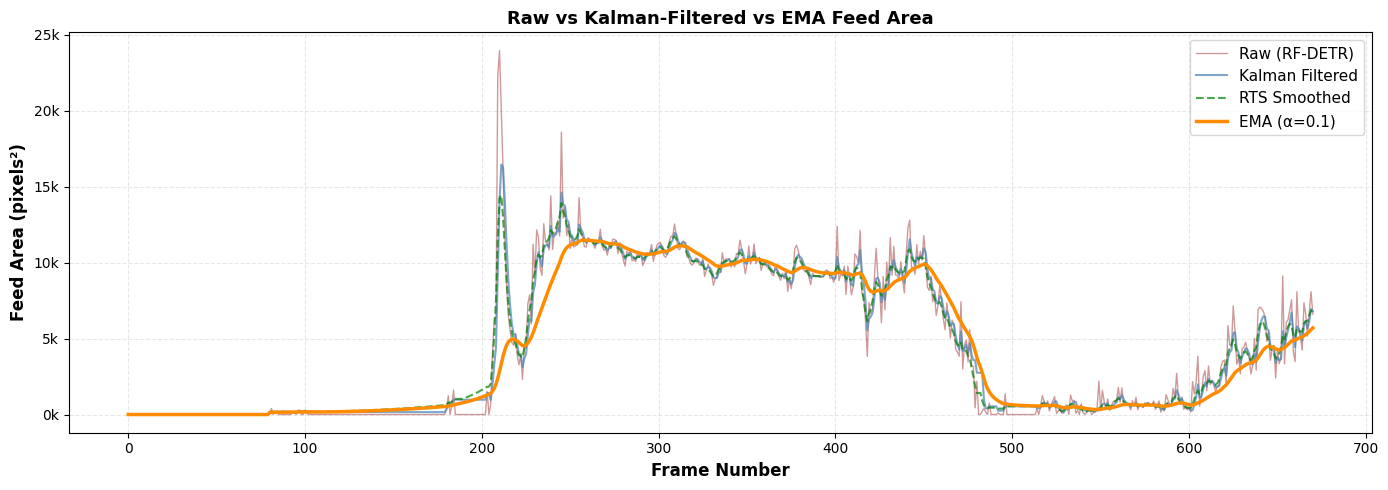

✓ Saved: rfdetr_consumption_rate_analysis.png


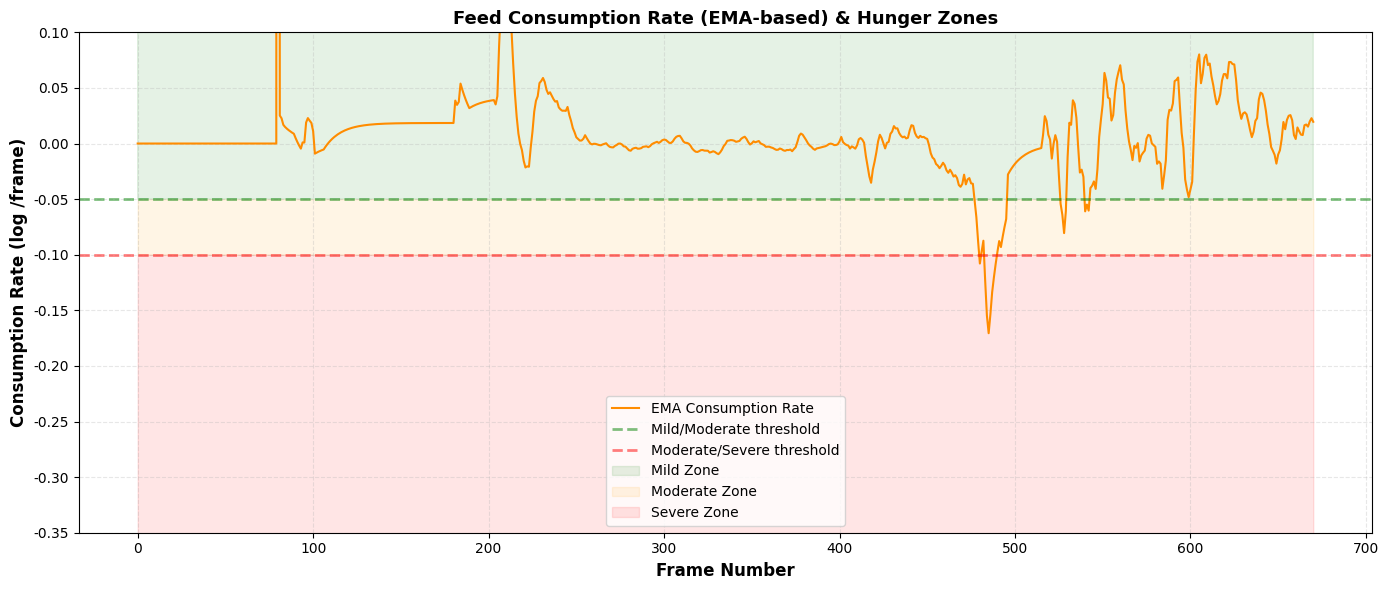

✓ Saved: rfdetr_detection_count_analysis.png


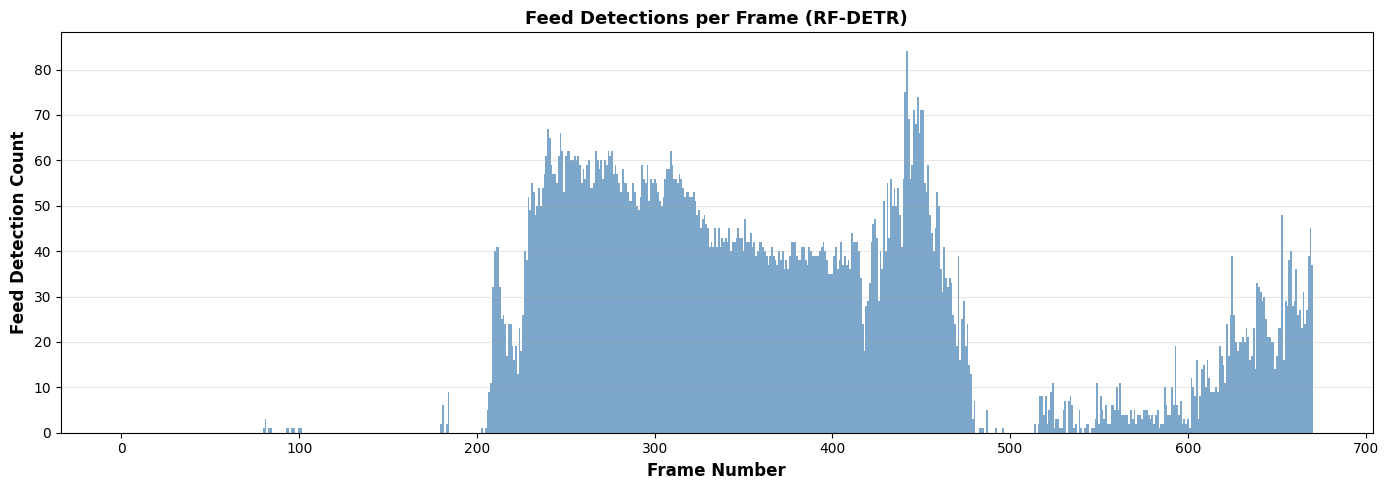

✓ Saved: rfdetr_hunger_distribution_analysis.png


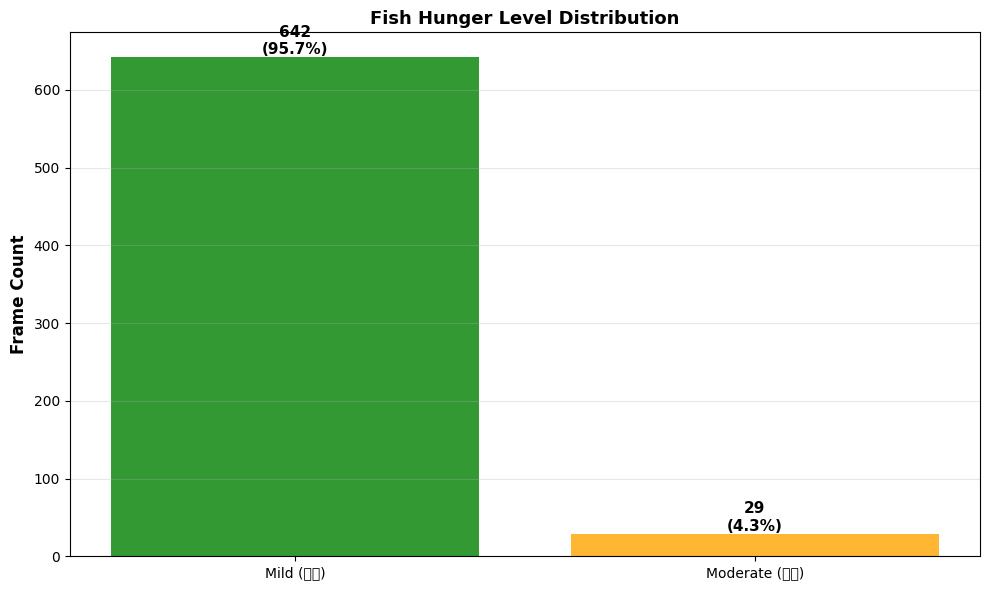

In [152]:
# ===== Plot 1: Raw vs Filtered Feed Area =====
fig1, ax1 = plt.subplots(figsize=(14, 5))
ax1.plot(frame_numbers, feed_areas_raw,
         label='Raw (RF-DETR)', color='darkred', alpha=0.4, linewidth=1)
ax1.plot(frame_numbers, feed_areas_filtered,
         label='Kalman Filtered', color='steelblue', linewidth=1.5, alpha=0.7)
ax1.plot(frame_numbers, smoothed_areas,
         label='RTS Smoothed', color='green', linewidth=1.5, linestyle='--', alpha=0.7)
ax1.plot(frame_numbers, ema_areas,
         label=f'EMA (α={CONFIG["ema_alpha"]})', color='darkorange', linewidth=2.5)
ax1.set_xlabel('Frame Number', fontsize=12, fontweight='bold')
ax1.set_ylabel('Feed Area (pixels²)', fontsize=12, fontweight='bold')
ax1.set_title('Raw vs Kalman-Filtered vs EMA Feed Area', fontsize=13, fontweight='bold')
ax1.legend(fontsize=11, loc='best')
ax1.grid(True, alpha=0.3, linestyle='--')
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x/1000)}k'))
plt.tight_layout()
plt.savefig('rfdetr_feed_area_analysis.png', dpi=150, bbox_inches='tight')
print('✓ Saved: rfdetr_feed_area_analysis.png')
plt.show()

# ===== Plot 2: Consumption Rate (from EMA) with Hunger Bands =====
fig2, ax2 = plt.subplots(figsize=(14, 6))
ax2.plot(frame_numbers, consumption_rate_log,
         color='darkorange', linewidth=1.5, label='EMA Consumption Rate')
ax2.axhline(y=-0.05, color='green', linestyle='--', linewidth=2, alpha=0.5, label='Mild/Moderate threshold')
ax2.axhline(y=-0.1, color='red', linestyle='--', linewidth=2, alpha=0.5, label='Moderate/Severe threshold')
ax2.fill_between(frame_numbers, -0.05, 0.5, alpha=0.1, color='green', label='Mild Zone')
ax2.fill_between(frame_numbers, -0.1, -0.05, alpha=0.1, color='orange', label='Moderate Zone')
ax2.fill_between(frame_numbers, -0.5, -0.1, alpha=0.1, color='red', label='Severe Zone')
ax2.set_xlabel('Frame Number', fontsize=12, fontweight='bold')
ax2.set_ylabel('Consumption Rate (log /frame)', fontsize=12, fontweight='bold')
ax2.set_title('Feed Consumption Rate (EMA-based) & Hunger Zones', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10, loc='best')
ax2.grid(True, alpha=0.3, linestyle='--')
ax2.set_ylim([-0.35, 0.1])
plt.tight_layout()
plt.savefig('rfdetr_consumption_rate_analysis.png', dpi=150, bbox_inches='tight')
print('✓ Saved: rfdetr_consumption_rate_analysis.png')
plt.show()

# ===== Plot 3: Detection Count per Frame =====
fig3, ax3 = plt.subplots(figsize=(14, 5))
ax3.bar(frame_numbers, detection_counts, color='steelblue', alpha=0.7, width=1)
ax3.set_xlabel('Frame Number', fontsize=12, fontweight='bold')
ax3.set_ylabel('Feed Detection Count', fontsize=12, fontweight='bold')
ax3.set_title('Feed Detections per Frame (RF-DETR)', fontsize=13, fontweight='bold')
ax3.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('rfdetr_detection_count_analysis.png', dpi=150, bbox_inches='tight')
print('✓ Saved: rfdetr_detection_count_analysis.png')
plt.show()

# ===== Plot 4: Hunger Level Distribution =====
fig4, ax4 = plt.subplots(figsize=(10, 6))
hunger_level_names = list(hunger_counts.keys())
hunger_level_counts = list(hunger_counts.values())
colors_map = {'Mild (輕度)': 'green', 'Moderate (中度)': 'orange', 'Severe (重度)': 'red'}
colors = [colors_map.get(level, 'gray') for level in hunger_level_names]
bars = ax4.bar(hunger_level_names, hunger_level_counts, color=colors, alpha=0.8)
ax4.set_ylabel('Frame Count', fontsize=12, fontweight='bold')
ax4.set_title('Fish Hunger Level Distribution', fontsize=13, fontweight='bold')
ax4.grid(True, alpha=0.3, axis='y')
for bar, count in zip(bars, hunger_level_counts):
    height = bar.get_height()
    ax4.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(count)}\n({count/len(hunger_levels)*100:.1f}%)',
             ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig('rfdetr_hunger_distribution_analysis.png', dpi=150, bbox_inches='tight')
print('✓ Saved: rfdetr_hunger_distribution_analysis.png')
plt.show()

## 6. Detailed Hunger Timeline

✓ Saved: rfdetr_hunger_timeline.png


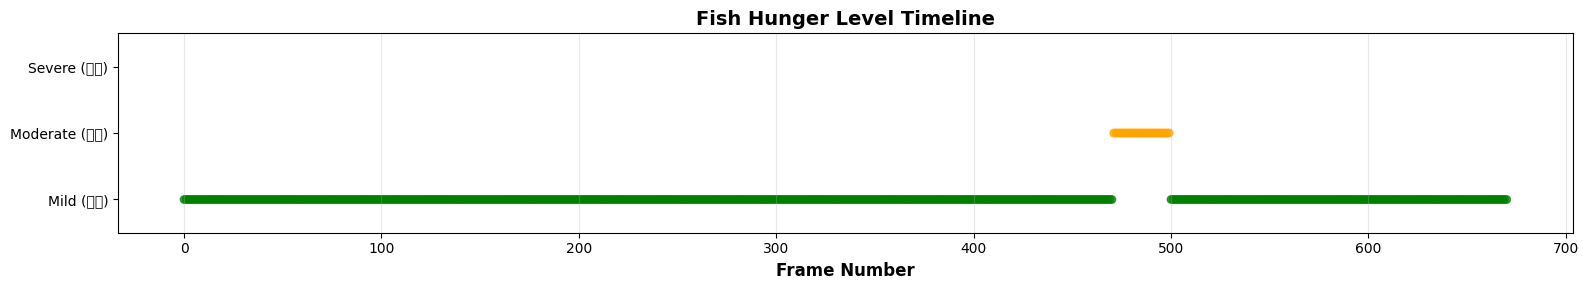

In [153]:
# Create hunger timeline visualization
fig, ax = plt.subplots(figsize=(16, 3))

# Map hunger levels to colors and numeric values
hunger_to_numeric = {'Mild (輕度)': 1, 'Moderate (中度)': 2, 'Severe (重度)': 3}
hunger_numeric = [hunger_to_numeric[level] for level in hunger_levels]
hunger_colors = {'Mild (輕度)': 'green', 'Moderate (中度)': 'orange', 'Severe (重度)': 'red'}

# Color each frame based on hunger level
colors = [hunger_colors[level] for level in hunger_levels]
ax.scatter(frame_numbers, hunger_numeric, c=colors, s=30, alpha=0.7)

ax.set_yticks([1, 2, 3])
ax.set_yticklabels(['Mild (輕度)', 'Moderate (中度)', 'Severe (重度)'])
ax.set_xlabel('Frame Number', fontsize=12, fontweight='bold')
ax.set_title('Fish Hunger Level Timeline', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, axis='x')
ax.set_ylim([0.5, 3.5])

plt.tight_layout()
plt.savefig('rfdetr_hunger_timeline.png', dpi=150, bbox_inches='tight')
print('✓ Saved: rfdetr_hunger_timeline.png')
plt.show()

## 7. Export Results

In [154]:
# Create comprehensive results dataframe
results_df = pd.DataFrame({
    'Frame': frame_numbers,
    'Time_sec': timestamps,
    'Raw_Feed_Area': feed_areas_raw,
    'Kalman_Filtered_Area': feed_areas_filtered,
    'RTS_Smoothed_Area': smoothed_areas,
    'EMA_Area': ema_areas,
    'EMA_Log_Area': ema_log_areas,
    'Consumption_Rate_Log': consumption_rate_log,
    'Consumption_Rate_Pct': consumption_rate_pct,
    'Feed_Detection_Count': detection_counts,
    'Hunger_Level': hunger_levels,
})

csv_path = 'rfdetr_inference_results.csv'
results_df.to_csv(csv_path, index=False)
print(f'✓ Saved: {csv_path}')

print('\nData preview (first 10 rows):')
print(results_df.head(10).to_string())

print('\n\nData summary:')
print(results_df.describe())

✓ Saved: rfdetr_inference_results.csv

Data preview (first 10 rows):
   Frame  Time_sec  Raw_Feed_Area  Kalman_Filtered_Area  RTS_Smoothed_Area  EMA_Area  EMA_Log_Area  Consumption_Rate_Log  Consumption_Rate_Pct  Feed_Detection_Count Hunger_Level
0      0  0.000000            0.0                   0.0                0.0       0.0           0.0                   0.0                   0.0                     0    Mild (輕度)
1      1  0.033351            0.0                   0.0                0.0       0.0           0.0                   0.0                   0.0                     0    Mild (輕度)
2      2  0.066701            0.0                   0.0                0.0       0.0           0.0                   0.0                   0.0                     0    Mild (輕度)
3      3  0.100052            0.0                   0.0                0.0       0.0           0.0                   0.0                   0.0                     0    Mild (輕度)
4      4  0.133403            0.0        

## 8. Final Report

In [155]:
print('\n' + '='*75)
print(' '*15 + 'RF-DETR INFERENCE + FISH HUNGER ASSESSMENT REPORT')
print('='*75)

print(f'\n【Basic Information】')
print(f'  Video File:           {CONFIG["video_path"]}')
print(f'  RF-DETR Model:        {CONFIG["model_path"]}')
print(f'  Processed Frames:     {len(frame_numbers)}')
print(f'  Video Duration:       {timestamps[-1]:.2f} seconds')
print(f'  FPS:                  {fps}')
print(f'  Confidence Threshold: {CONFIG["confidence_threshold"]}')

print(f'\n【Model Parameters】')
print(f'  sigma_R (measurement noise):  {CONFIG["sigma_R"]}')
print(f'  sigma_Q (process noise):      {CONFIG["sigma_Q"]}')

print(f'\n【Feed Area Statistics】')
print(f'  Raw (RF-DETR):        {feed_areas_raw.min():,.0f} ~ {feed_areas_raw.max():,.0f} pixels²')
print(f'  Kalman Filtered:      {feed_areas_filtered.min():,.0f} ~ {feed_areas_filtered.max():,.0f} pixels²')
print(f'  RTS Smoothed:         {smoothed_areas.min():,.0f} ~ {smoothed_areas.max():,.0f} pixels²')
print(f'  Mean smoothed area:   {smoothed_areas.mean():,.0f} pixels²')

print(f'\n【Feed Detection Statistics】')
print(f'  Total detections:     {detection_counts.sum():.0f}')
print(f'  Mean per frame:       {detection_counts.mean():.2f}')
print(f'  Frames with feed:     {(detection_counts > 0).sum()}/{len(detection_counts)}')

print(f'\n【Consumption Analysis】')
print(f'  Mean consumption rate:     {consumption_rate_log.mean():.5f} /frame')
print(f'  Consumption intensity:     {consumption_rate_log.mean()*100:.3f}% per frame')
print(f'  Std deviation:             {consumption_rate_log.std():.5f}')
print(f'  Min (fastest growth):      {consumption_rate_log.max():.5f} /frame')
print(f'  Max (fastest consumption): {consumption_rate_log.min():.5f} /frame')

print(f'\n【Fish Hunger Assessment】')
print(f'  Overall Hunger Level:  {overall_hunger}')
print(f'  Average Consumption:   {overall_consumption:.5f} /frame')
print(f'  Intensity per second:  {overall_consumption*fps*100:.2f}% /sec')
print(f'\n  Hunger Distribution:')
for level in ['Mild (輕度)', 'Moderate (中度)', 'Severe (重度)']:
    count = hunger_counts.get(level, 0)
    pct = (count / len(hunger_levels)) * 100
    print(f'    {level:20s}: {count:4d} frames ({pct:5.1f}%)')

print(f'\n【Output Files】')
print(f'  ✓ rfdetr_inference_analysis.png')
print(f'  ✓ rfdetr_hunger_timeline.png')
print(f'  ✓ rfdetr_inference_results.csv')

print('\n' + '='*75)
print('Analysis Complete!')
print('='*75)


               RF-DETR INFERENCE + FISH HUNGER ASSESSMENT REPORT

【Basic Information】
  Video File:           ../data/toilet1.mp4
  RF-DETR Model:        ../models/rf-detr-fish-regular.pth
  Processed Frames:     671
  Video Duration:       22.34 seconds
  FPS:                  29.984359871899905
  Confidence Threshold: 0.3

【Model Parameters】
  sigma_R (measurement noise):  0.5
  sigma_Q (process noise):      0.3

【Feed Area Statistics】
  Raw (RF-DETR):        0 ~ 23,967 pixels²
  Kalman Filtered:      0 ~ 16,458 pixels²
  RTS Smoothed:         0 ~ 14,430 pixels²
  Mean smoothed area:   4,476 pixels²

【Feed Detection Statistics】
  Total detections:     14342
  Mean per frame:       21.37
  Frames with feed:     449/671

【Consumption Analysis】
  Mean consumption rate:     0.01289 /frame
  Consumption intensity:     1.289% per frame
  Std deviation:             0.19341
  Min (fastest growth):      4.94630 /frame
  Max (fastest consumption): -0.17058 /frame

【Fish Hunger Assessment】
  O